# 07 — Following a car when confidence briefly falls

Think of a guard following a car with a numbered sticker. One slightly unclear
picture should not automatically give that same car a new sticker. But a weak
picture must not create a new car or invent a crossing.

Our **separate experimental tracker** can use a weaker, nearby, unambiguous box
to keep an existing identity. A strong box is still needed to start an identity.
Weak boxes erase the crossing memory, so we never use them to guess a crossing.
An actually missing observation still breaks the identity. The original product
tracker is unchanged; the candidate has not been promoted.

This notebook displays saved reports only: no detector inference, training,
tuning, raw final-frame decoding or final reevaluation. Notebook06 remains a
dated record of the earlier failed identity check.

Data: **DAVIS2017**, source **SRC-DS-012**, [DAVIS authors](https://davischallenge.org/),
Pont-Tuset et al. (2017), Perazzi et al. (2016), aggregate
[CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/).
Foreground annotations intentionally omit other road users. Physical fps is
unknown; every timeline below uses frame index.

In [1]:
from pathlib import Path
import json, csv, hashlib
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from html import escape

ROOT=Path.cwd().resolve()
if not (ROOT/'data/automation_state.json').exists(): ROOT=ROOT.parent
assert (ROOT/'data/automation_state.json').exists()
D="FLOW-CONTINUATION-20261025T145043485311Z"
F="FLOW-SEQUENCE-FINAL-20261025T145525078714Z"
development=json.loads((ROOT/'experiments/results'/D/'run.json').read_text(encoding='utf-8'))
final=json.loads((ROOT/'experiments/results'/F/'run.json').read_text(encoding='utf-8'))
for run in [development,final]:
    snapshots=json.loads((ROOT/'experiments/results'/run['run_id']/'implementation_sources.json').read_text(encoding='utf-8'))
    for path,checksum in run['source_hashes'].items():
        assert hashlib.sha256(snapshots[path]['source'].encode()).hexdigest()==checksum

def table(rows, columns):
    head=''.join('<th style="padding:8px;text-align:left">'+escape(str(c))+'</th>' for c in columns)
    body=''.join('<tr>'+''.join('<td style="padding:8px;border-bottom:1px solid #ddd">'+escape(str(v))+'</td>' for v in row)+'</tr>' for row in rows)
    display(HTML('<table><thead><tr>'+head+'</tr></thead><tbody>'+body+'</tbody></table>'))

print('These are saved development/final reports, not new experiments.')

These are saved development/final reports, not new experiments.


## 1. What changed in development?

At frame26the real detector still produced a box close to the publisher label,
but its confidence was about0.637, below the tracker's0.7cutoff. The original
tracker lost that car's identity. The candidate accepts scores from0.5only for
an unambiguous existing identity, keeps the actual score and forbids weak births.
The line stayed at the previously frozen x694; there was no threshold/line search.

This idea came from inspecting the same development footage, so it needs a
separate final check. One car repeatedly seen is still only one car.

In [2]:
before=development['baseline']['metrics']
after=development['metrics']
table([
    ['Visible selected-car frames', before['scored_visible_car_frames'], after['scored_visible_car_frames']],
    ['Matched tracking coverage', f"{before['matched_track_coverage']:.1%}", f"{after['matched_track_coverage']:.1%}"],
    ['Dominant identity coverage', f"{before['dominant_track_fraction']:.1%}", f"{after['dominant_track_fraction']:.1%}"],
    ['Recovered labelled crossings', f"{before['recovered_events']}/{before['reference_events']}", f"{after['recovered_events']}/{after['reference_events']}"],
    ['Development gate passed', False, development['counting_final_qualified']],
], ['Saved development observation','Original tracker','Candidate'])
print('Weak identity continuations:',development['weak_continuations'])

Saved development observation,Original tracker,Candidate
Visible selected-car frames,75,75
Matched tracking coverage,98.7%,100.0%
Dominant identity coverage,70.7%,100.0%
Recovered labelled crossings,1/1,1/1
Development gate passed,False,True


Weak identity continuations: 1


## 2. The identity timeline

The numbers are arbitrary IDs, like sticker numbers. Their numerical size is not
a quality score. A jump from1to3means the same labelled car was given another
identity. The gap at frame26is the missing original track. This plot uses the
saved development CSV, not another detector or scoring run.

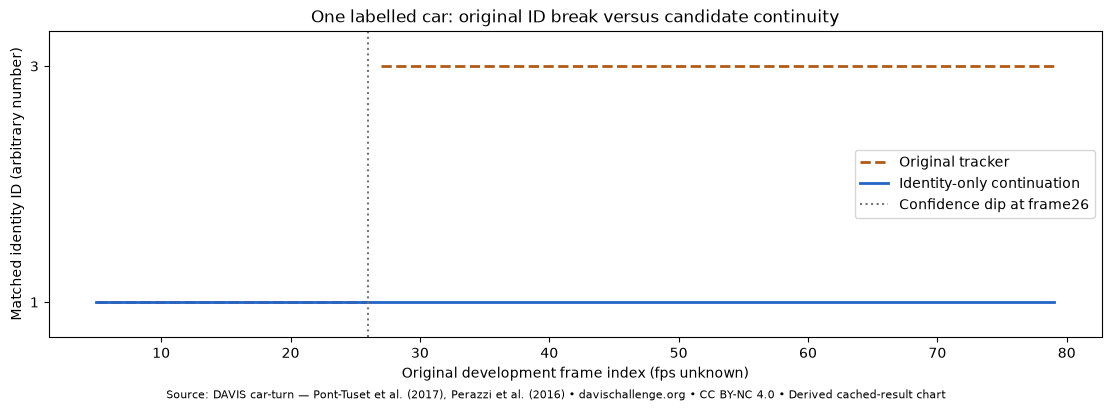

In [3]:
with (ROOT/'experiments/results'/D/'observations.csv').open(encoding='utf-8',newline='') as stream:
    observations=[r for r in csv.DictReader(stream) if int(r['frame_index'])>=5]
frames=[int(r['frame_index']) for r in observations]
original=[float(r['baseline_track_id']) if r['baseline_track_id'] else float('nan') for r in observations]
candidate=[float(r['candidate_track_id']) if r['candidate_track_id'] else float('nan') for r in observations]
fig,ax=plt.subplots(figsize=(11,4),layout='constrained')
ax.step(frames,original,where='post',linestyle='--',color='#b15b16',linewidth=2,label='Original tracker')
ax.step(frames,candidate,where='post',color='#2364c7',linewidth=2,label='Identity-only continuation')
ax.axvline(26,linestyle=':',color='#777777',label='Confidence dip at frame26')
ax.set(xlabel='Original development frame index (fps unknown)',ylabel='Matched identity ID (arbitrary number)',
       title='One labelled car: original ID break versus candidate continuity',yticks=[1,3],ylim=(.7,3.3))
ax.legend(loc='center right')
fig.supxlabel('Source: DAVIS car-turn — Pont-Tuset et al. (2017), Perazzi et al. (2016) • davischallenge.org • CC BY-NC 4.0 • Derived cached-result chart',fontsize=8)
path=ROOT/'reports/figures/flow_identity_development_comparison.png'
path.parent.mkdir(parents=True,exist_ok=True)
fig.savefig(path,dpi=130,facecolor='white')
plt.show()

## 3. What did the separate final exam tell us?

The entire75frame `car-roundabout` sequence was reserved. A durable one-use claim
was written **before** any pixels were decoded. The frozen rule uses its first
five labelled frames for operator-like setup, then scores the remaining70frames.

Both trackers retained the labelled car well. However, that selected car never
crossed the frozen line. We cannot grade crossing recovery when there is no
reference crossing. One predicted crossing is unmatched to the selected object;
the partial labels cannot tell us whether it is a valid unlabelled vehicle or a
false positive. It is **not** scored as a proven error or success.

The overall final gate therefore fails. We do not move the line to improve the
score or rerun a changed method. The whole sequence, including setup, is now
consumed. Fresh labelled footage is required for further final comparisons.

In [4]:
b=final['baseline']['metrics']; m=final['metrics']
table([
    ['Scored selected-car frames',b['scored_visible_car_frames'],m['scored_visible_car_frames']],
    ['Matched track coverage',f"{b['matched_track_coverage']:.1%}",f"{m['matched_track_coverage']:.1%}"],
    ['Dominant identity coverage',f"{b['dominant_track_fraction']:.1%}",f"{m['dominant_track_fraction']:.1%}"],
    ['Labelled reference crossings',b['reference_events'],m['reference_events']],
    ['Crossing recovery', 'Not evaluable' if b['annotated_event_recall'] is None else b['annotated_event_recall'],
                          'Not evaluable' if m['annotated_event_recall'] is None else m['annotated_event_recall']],
    ['Unmatched predicted events (not exhaustive false positives)',b['unmatched_predicted_events'],m['unmatched_predicted_events']],
], ['Saved final observation','Original tracker','Candidate'])
print('Overall final gate passed:',final['final_gate_passed'])
print('Entire final sequence consumed:',final['reserved_sequence_consumed'])
print('Production model/tracker promoted:',final['production_promoted'])

Saved final observation,Original tracker,Candidate
Scored selected-car frames,70,70
Matched track coverage,100.0%,100.0%
Dominant identity coverage,100.0%,100.0%
Labelled reference crossings,0,0
Crossing recovery,Not evaluable,Not evaluable
Unmatched predicted events (not exhaustive false positives),1,1


Overall final gate passed: False
Entire final sequence consumed: True
Production model/tracker promoted: False


## 4. Where the evidence is saved

- Development: `experiments/results/FLOW-CONTINUATION-20261025T145043485311Z/`, including `protocol.json`,
  `run.json`, exact source snapshots and per-frame `observations.csv`.
- Final: `experiments/results/FLOW-SEQUENCE-FINAL-20261025T145525078714Z/`, including its frozen
  `protocol.json`, `selection.json`, `setup.json`, `observations.csv`, full
  saved prediction records and metrics.
- Durable one-use claim/outcome: `data/sequence_holdout_claims/`.
- Cards: `models/flow_continuation_development.json` and
  `models/davis_sequence_final.json`.
- Original labelled JPEG/mask pairs and licences: the paths in notebook06 and
  `docs/LABELLED_SEQUENCE_GUIDE.md`; no original data was edited.

159software tests include500randomized synthetic weak-observation cases. These
test rules such as “a weak box cannot create a new car or crossing”; they do
not measure real-world accuracy. An initial scorer configuration error is
preserved as an uncounted failed attempt, not hidden.

**Practise explaining:** Why is retaining an ID different from deciding a car
entered a car park? Why can a software test pass while a final scientific gate
fails? Why is zero reference crossings an unavailable score, rather than perfect
counting? These questions help you learn; the notebook does not prove mastery.